## Objectives & Metrics:

Objective:
To classify a person as Healthy, Needs Attention or Critical from their work, psychological and lifestyle data, to help identify people at mental health risk people early. 


Metrics: 
Since i am dealing with a a categorical 'target', i will have to use classificatin metrics to define the model. They are: 
1. Accuracy: To determine how well the model can predict the right answer from the whole data.
2. Macro F1-score: a balanced score across the three classes, so the small class isnt ignored, since we have imbalanced classes in the target.
3. Recall for Critical: To determine how many of all the Critical people, the model can catch. As missing a Critical person for this model is the worst mistake.
4. ROC-AUC: how well the model seperates one class from the another.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score

## DATA CLEANING

In [3]:
df = pd.read_csv('mental_health_dataset.csv')
df.head()

,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.0,67,Hybrid,...,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.0,44,Hybrid,...,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.0,60,No,...,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.0,25,Yes,...,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,NaN,52,No,...,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


In [4]:
df1 = df.copy()

In [5]:
df1.head()

,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.0,67,Hybrid,...,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.0,44,Hybrid,...,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.0,60,No,...,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.0,25,Yes,...,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,NaN,52,No,...,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


In [6]:
print(df1.shape)
df1.info()

(50000, 40)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 40 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Person_ID                      50000 non-null  int64  
 1   Age                            49750 non-null  float64
 2   Gender                         50000 non-null  str    
 3   Country                        50000 non-null  str    
 4   Occupation                     50000 non-null  str    
 5   Education_Level                50000 non-null  str    
 6   Employment_Status              50000 non-null  str    
 7   Monthly_Income_USD             48550 non-null  float64
 8   Work_Hours_Per_Week            50000 non-null  int64  
 9   Remote_Work                    50000 non-null  str    
 10  Job_Satisfaction               49500 non-null  float64
 11  Work_Life_Balance              49350 non-null  float64
 12  Sleep_Hours                    49050 non-null

In [7]:
print(df1.isnull().sum())

Person_ID                           0
Age                               250
Gender                              0
Country                             0
Occupation                          0
Education_Level                     0
Employment_Status                   0
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Remote_Work                         0
Job_Satisfaction                  500
Work_Life_Balance                 650
Sleep_Hours                       950
Sleep_Quality                       0
Stress_Level                        0
Anxiety_Score                     800
Depression_Score                  850
Mood_Score                        900
Emotional_Stability                 0
Physical_Activity_Hours          1100
Exercise_Frequency                  0
Meditation_Minutes               1200
Screen_Time_Hours                 850
Social_Media_Hours                600
Gaming_Hours                      750
Coffee_Cups_Per_Day                 0
Alcohol_Cons

In [8]:
df.isnull().mean() *100
# to understand the percentage of missing values in each column


Person_ID                        0.0
Age                              0.5
Gender                           0.0
Country                          0.0
Occupation                       0.0
Education_Level                  0.0
Employment_Status                0.0
Monthly_Income_USD               2.9
Work_Hours_Per_Week              0.0
Remote_Work                      0.0
Job_Satisfaction                 1.0
Work_Life_Balance                1.3
Sleep_Hours                      1.9
Sleep_Quality                    0.0
Stress_Level                     0.0
Anxiety_Score                    1.6
Depression_Score                 1.7
Mood_Score                       1.8
Emotional_Stability              0.0
Physical_Activity_Hours          2.2
Exercise_Frequency               0.0
Meditation_Minutes               2.4
Screen_Time_Hours                1.7
Social_Media_Hours               1.2
Gaming_Hours                     1.5
Coffee_Cups_Per_Day              0.0
Alcohol_Consumption              0.0
S

In [9]:
print(df1.duplicated().sum())
print(df1['Person_ID'].duplicated().sum())

0
0


N:B - No duplicates values found

In [10]:
missing_datavalues = df1.isnull().sum()
missing_datavalues[missing_datavalues > 0]
# to check the columns with missing values and their counts

Age                         250
Monthly_Income_USD         1450
Job_Satisfaction            500
Work_Life_Balance           650
Sleep_Hours                 950
Anxiety_Score               800
Depression_Score            850
Mood_Score                  900
Physical_Activity_Hours    1100
Meditation_Minutes         1200
Screen_Time_Hours           850
Social_Media_Hours          600
Gaming_Hours                750
Therapy_Attendance          400
Life_Satisfaction           700
Productivity_Score          950
dtype: int64

In [11]:
num_cols = df1.select_dtypes(include='number').columns
(df1[num_cols] < 0).sum().sum()
# to check if there are any negative values in the numerical columns

np.int64(0)

In [12]:
df1.describe().T[['min', 'max', 'mean']]
# to check the minimum, maximum and mean values of the numerical columns

,min,max,mean
Person_ID,1.0,50000.0,25000.500000
Age,18.0,65.0,41.448181
Monthly_Income_USD,500.0,12000.0,6251.281524
Work_Hours_Per_Week,20.0,70.0,44.946160
Job_Satisfaction,1.0,10.0,5.499051
Work_Life_Balance,1.0,10.0,5.504397
Sleep_Hours,4.0,10.0,6.997445
Anxiety_Score,0.0,100.0,40.449045
Depression_Score,0.0,100.0,40.601160
Mood_Score,0.0,100.0,59.622994


## OUTLIER DETECTION

In [13]:
# to check for outliers in the numerical columns using the IQR method
for col in num_cols.drop('Person_ID'):
    q1, q3 = df1[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    
    n = ((df1[col] < q1 - 1.5*iqr) | (df1[col] > q3 + 1.5*iqr)).sum()
    print(col, n)

Age 0
Monthly_Income_USD 0
Work_Hours_Per_Week 0
Job_Satisfaction 0
Work_Life_Balance 0
Sleep_Hours 0
Anxiety_Score 0
Depression_Score 0
Mood_Score 0
Emotional_Stability 0
Physical_Activity_Hours 0
Meditation_Minutes 0
Screen_Time_Hours 0
Social_Media_Hours 0
Gaming_Hours 0
Coffee_Cups_Per_Day 0
Life_Satisfaction 0
Productivity_Score 0
Absenteeism_Days 0
Burnout_Score 0


Findings: "No duplicates, negative values or outliers were found in this dataset; 16 columns have 0.5% to 2.9% missing values."

## TARGET SETTING

In [14]:
TARGET = 'Mental_Health_Status'
counts = display((df1[TARGET]).value_counts())

percentages = display((df1[TARGET]).value_counts(normalize =True).round(3) * 100)
# to check the distribution of the target variable and its percentages

Mental_Health_Status
Healthy            25369
Needs Attention    14096
Critical           10535
Name: count, dtype: int64

Mental_Health_Status
Healthy            50.7
Needs Attention    28.2
Critical           21.1
Name: proportion, dtype: float64

TARGET LEAKAGE DICOVERY

To avoid giving answers to the model, i had to analyse the 'Burnout_Risk' & 'Burnout_Score'columns.

The Burnout_Risk feature was crosstabbed with the target and it revealed that "Low" already predicted "Healthy", "High" predicted "Critical" and "Moderate" predicting "Needs Attenntion".

The Burnout_Score also did the same

In [15]:
display(pd.crosstab(df1['Burnout_Risk'], df1[TARGET]))
display(df1.groupby(TARGET)['Burnout_Score'].agg(['min', 'max']))

Mental_Health_Status,Critical,Healthy,Needs Attention
Burnout_Risk,,,
High,9851,0,0
Low,0,25369,0
Moderate,684,0,14096


,min,max
Mental_Health_Status,,
Critical,46,100
Healthy,0,39
Needs Attention,40,64


In [16]:
print(df1.columns.tolist())

['Person_ID', 'Age', 'Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Remote_Work', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Sleep_Quality', 'Stress_Level', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Exercise_Frequency', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


In [17]:
df_model = df1.drop(columns = ['Person_ID', 'Burnout_Score', 'Burnout_Risk', 'AI_Wellness_Recommendation'])
print(df_model.shape)

(50000, 36)


#### Colums Dropped: 
1. Person_ID: This is just a label and does not have a particular meaning.
2. Burnout_Score & Burnout_Risk: They are leakages as shown above.
3. AI_Wellness_Recommendation: This is an output that was made after judging the risk, and is the same across all classes, so no signal associated. 

## ENCODING

In [18]:
ordinal_maps = {
    'Education_Level':    {'High School': 0, 'Diploma': 1, 'Bachelor': 2, 'Master': 3, 'PhD': 4},
    'Sleep_Quality':      {'Poor': 0, 'Average': 1, 'Good': 2, 'Excellent': 3},
    'Stress_Level':       {'Low': 0, 'Moderate': 1, 'High': 2},
    'Exercise_Frequency': {'Never': 0, 'Rarely': 1, 'Weekly': 2, 'Daily': 3},
    'Support_System':     {'Poor': 0, 'Average': 1, 'Good': 2, 'Excellent': 3},
}
for col, mapping in ordinal_maps.items():
    df_model[col] = df_model[col].map(mapping)

binary_cols = ['Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress',
               'Family_History_Mental_Illness', 'Therapy_Attendance']
for col in binary_cols:
    df_model[col] = df_model[col].map({'Yes': 1, 'No': 0})

df_model = pd.get_dummies(df_model,
                          columns=['Gender', 'Country', 'Occupation',
                                   'Employment_Status', 'Remote_Work'],
                          dtype=int)

df_model[TARGET] = df_model[TARGET].map(
    {'Healthy': 0, 'Needs Attention': 1, 'Critical': 2})

In [19]:
print(df_model.shape)
print(df_model.select_dtypes(exclude='number').columns.tolist())

(50000, 86)
[]


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import accuracy_score

In [21]:
x = df_model.drop(columns=[TARGET])   # the inputs
y = df_model[TARGET]                  # the output

X_train, X_test, Y_train, Y_test = train_test_split(
    x, y, test_size=0.20, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)

(40000, 85) (10000, 85)


In [22]:
x.head()

,Age,Education_Level,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Sleep_Quality,Stress_Level,Anxiety_Score,...,Occupation_Software Engineer,Occupation_Student,Occupation_Teacher,Employment_Status_Employed,Employment_Status_Self-Employed,Employment_Status_Student,Employment_Status_Unemployed,Remote_Work_Hybrid,Remote_Work_No,Remote_Work_Yes
0,58.0,1,2786.0,67,3.0,7.0,4.6,0,2,74.0,...,0,0,0,1,0,0,0,1,0,0
1,24.0,2,8027.0,44,5.0,8.0,4.7,0,1,58.0,...,0,0,0,0,0,1,0,1,0,0
2,59.0,4,3177.0,60,8.0,7.0,6.3,1,1,54.0,...,0,0,0,1,0,0,0,0,1,0
3,65.0,3,4093.0,25,2.0,9.0,7.1,2,0,12.0,...,0,0,0,0,1,0,0,0,0,1
4,64.0,1,NaN,52,1.0,4.0,9.1,3,0,25.0,...,0,0,0,0,0,1,0,0,1,0


In [23]:
y.head()

0    2
1    2
2    1
3    0
4    0
Name: Mental_Health_Status, dtype: int64

In [24]:
X_train.head()


,Age,Education_Level,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Sleep_Quality,Stress_Level,Anxiety_Score,...,Occupation_Software Engineer,Occupation_Student,Occupation_Teacher,Employment_Status_Employed,Employment_Status_Self-Employed,Employment_Status_Student,Employment_Status_Unemployed,Remote_Work_Hybrid,Remote_Work_No,Remote_Work_Yes
35519,48.0,4,5267.0,43,1.0,10.0,5.8,1,2,71.0,...,0,0,0,1,0,0,0,0,1,0
22493,29.0,3,2440.0,57,9.0,8.0,6.8,1,1,NaN,...,0,0,0,0,0,1,0,1,0,0
32984,32.0,2,7134.0,56,9.0,5.0,5.5,1,2,100.0,...,0,0,0,0,0,0,1,0,1,0
21111,63.0,2,3787.0,39,7.0,2.0,9.8,3,0,30.0,...,0,0,0,0,0,1,0,1,0,0
517,33.0,4,5769.0,43,6.0,1.0,8.0,2,1,31.0,...,0,0,0,1,0,0,0,0,1,0


In [25]:
X_test.head()

,Age,Education_Level,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Sleep_Quality,Stress_Level,Anxiety_Score,...,Occupation_Software Engineer,Occupation_Student,Occupation_Teacher,Employment_Status_Employed,Employment_Status_Self-Employed,Employment_Status_Student,Employment_Status_Unemployed,Remote_Work_Hybrid,Remote_Work_No,Remote_Work_Yes
40158,24.0,4,927.0,33,2.0,9.0,7.2,2,1,26.0,...,0,0,0,0,1,0,0,0,1,0
20837,22.0,2,1696.0,54,7.0,10.0,8.0,2,1,48.0,...,0,0,0,0,0,0,1,0,1,0
35301,37.0,4,10112.0,41,4.0,5.0,NaN,2,0,22.0,...,0,1,0,0,1,0,0,0,0,1
20678,57.0,3,11962.0,35,9.0,6.0,5.2,1,1,50.0,...,0,1,0,0,0,0,1,0,1,0
38973,55.0,0,5715.0,39,9.0,9.0,4.9,0,0,0.0,...,0,0,0,0,0,0,1,0,0,1


In [26]:
Y_train.head()

35519    2
22493    1
32984    2
21111    0
517      0
Name: Mental_Health_Status, dtype: int64

In [27]:
Y_test.head()

40158    0
20837    2
35301    0
20678    1
38973    0
Name: Mental_Health_Status, dtype: int64

## FILLING UP MISSING VALUES

In [28]:
# to check for missing values in the training and testing datasets before imputation
print('Missing before:', X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

fill_values = X_train.median()
fill_values['Therapy_Attendance'] = X_train['Therapy_Attendance'].mode()[0] 
# mode imputation for the categorical column 'Therapy_Attendance'

X_train = X_train.fillna(fill_values)
X_test = X_test.fillna(fill_values)

print('Missing after:', X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Missing before: 10358 2542
Missing after: 0 0


Findings: "Mising values were imputed with the training-set median(mode for Therapy_Attendance), applied to both sets to avoid data leakage."

## EXPLORATORY DATA ANALYSIS (EDA)

In [29]:
order = ['Healthy', 'Needs Attention', 'Critical']
colors = {'Healthy': 'green', 'Needs Attention': 'coral', 'Critical': 'red'}

num_list = [col for col in df1.select_dtypes(include='number').columns
             if col not in ['Person_ID', 'Burnout_Score']]
# to get the list of numerical columns excluding 'Person_ID' and 'Burnout_Score'

### CHART 1

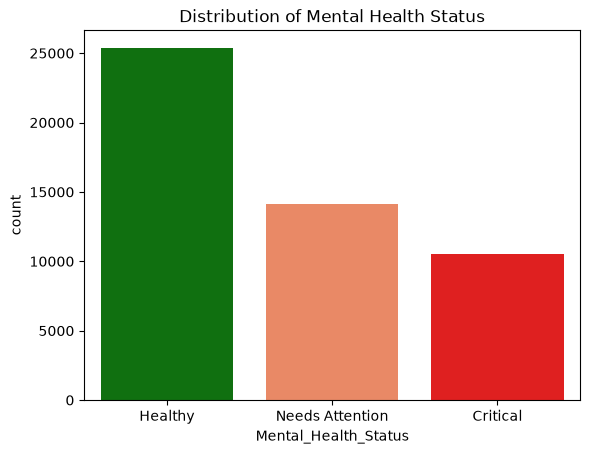

In [30]:
sns.countplot(data=df1, x=TARGET, order=order, hue=TARGET, palette=colors, legend=False)
plt.title('Distribution of Mental Health Status')
plt.show()

Fig 1.1(Target Distribution): "The target variable, Mental_Health_Status, reveals a mild class imbalance. The largest category is 'Healthy' with 25,369 rows, making up 50.7% of the total dataset. The remaining half of the population is split down into individuals who 'Need Attention' (14,096 rows at 28.2%) and those in a 'Critical' state (10,535 rows at 21.1%). Because the dataset has unequal categories, this imbalance will be handled during model training to ensure fair predictive accuracy."


### CHART 2: Key psychological features by group/mental health score  (boxplots)

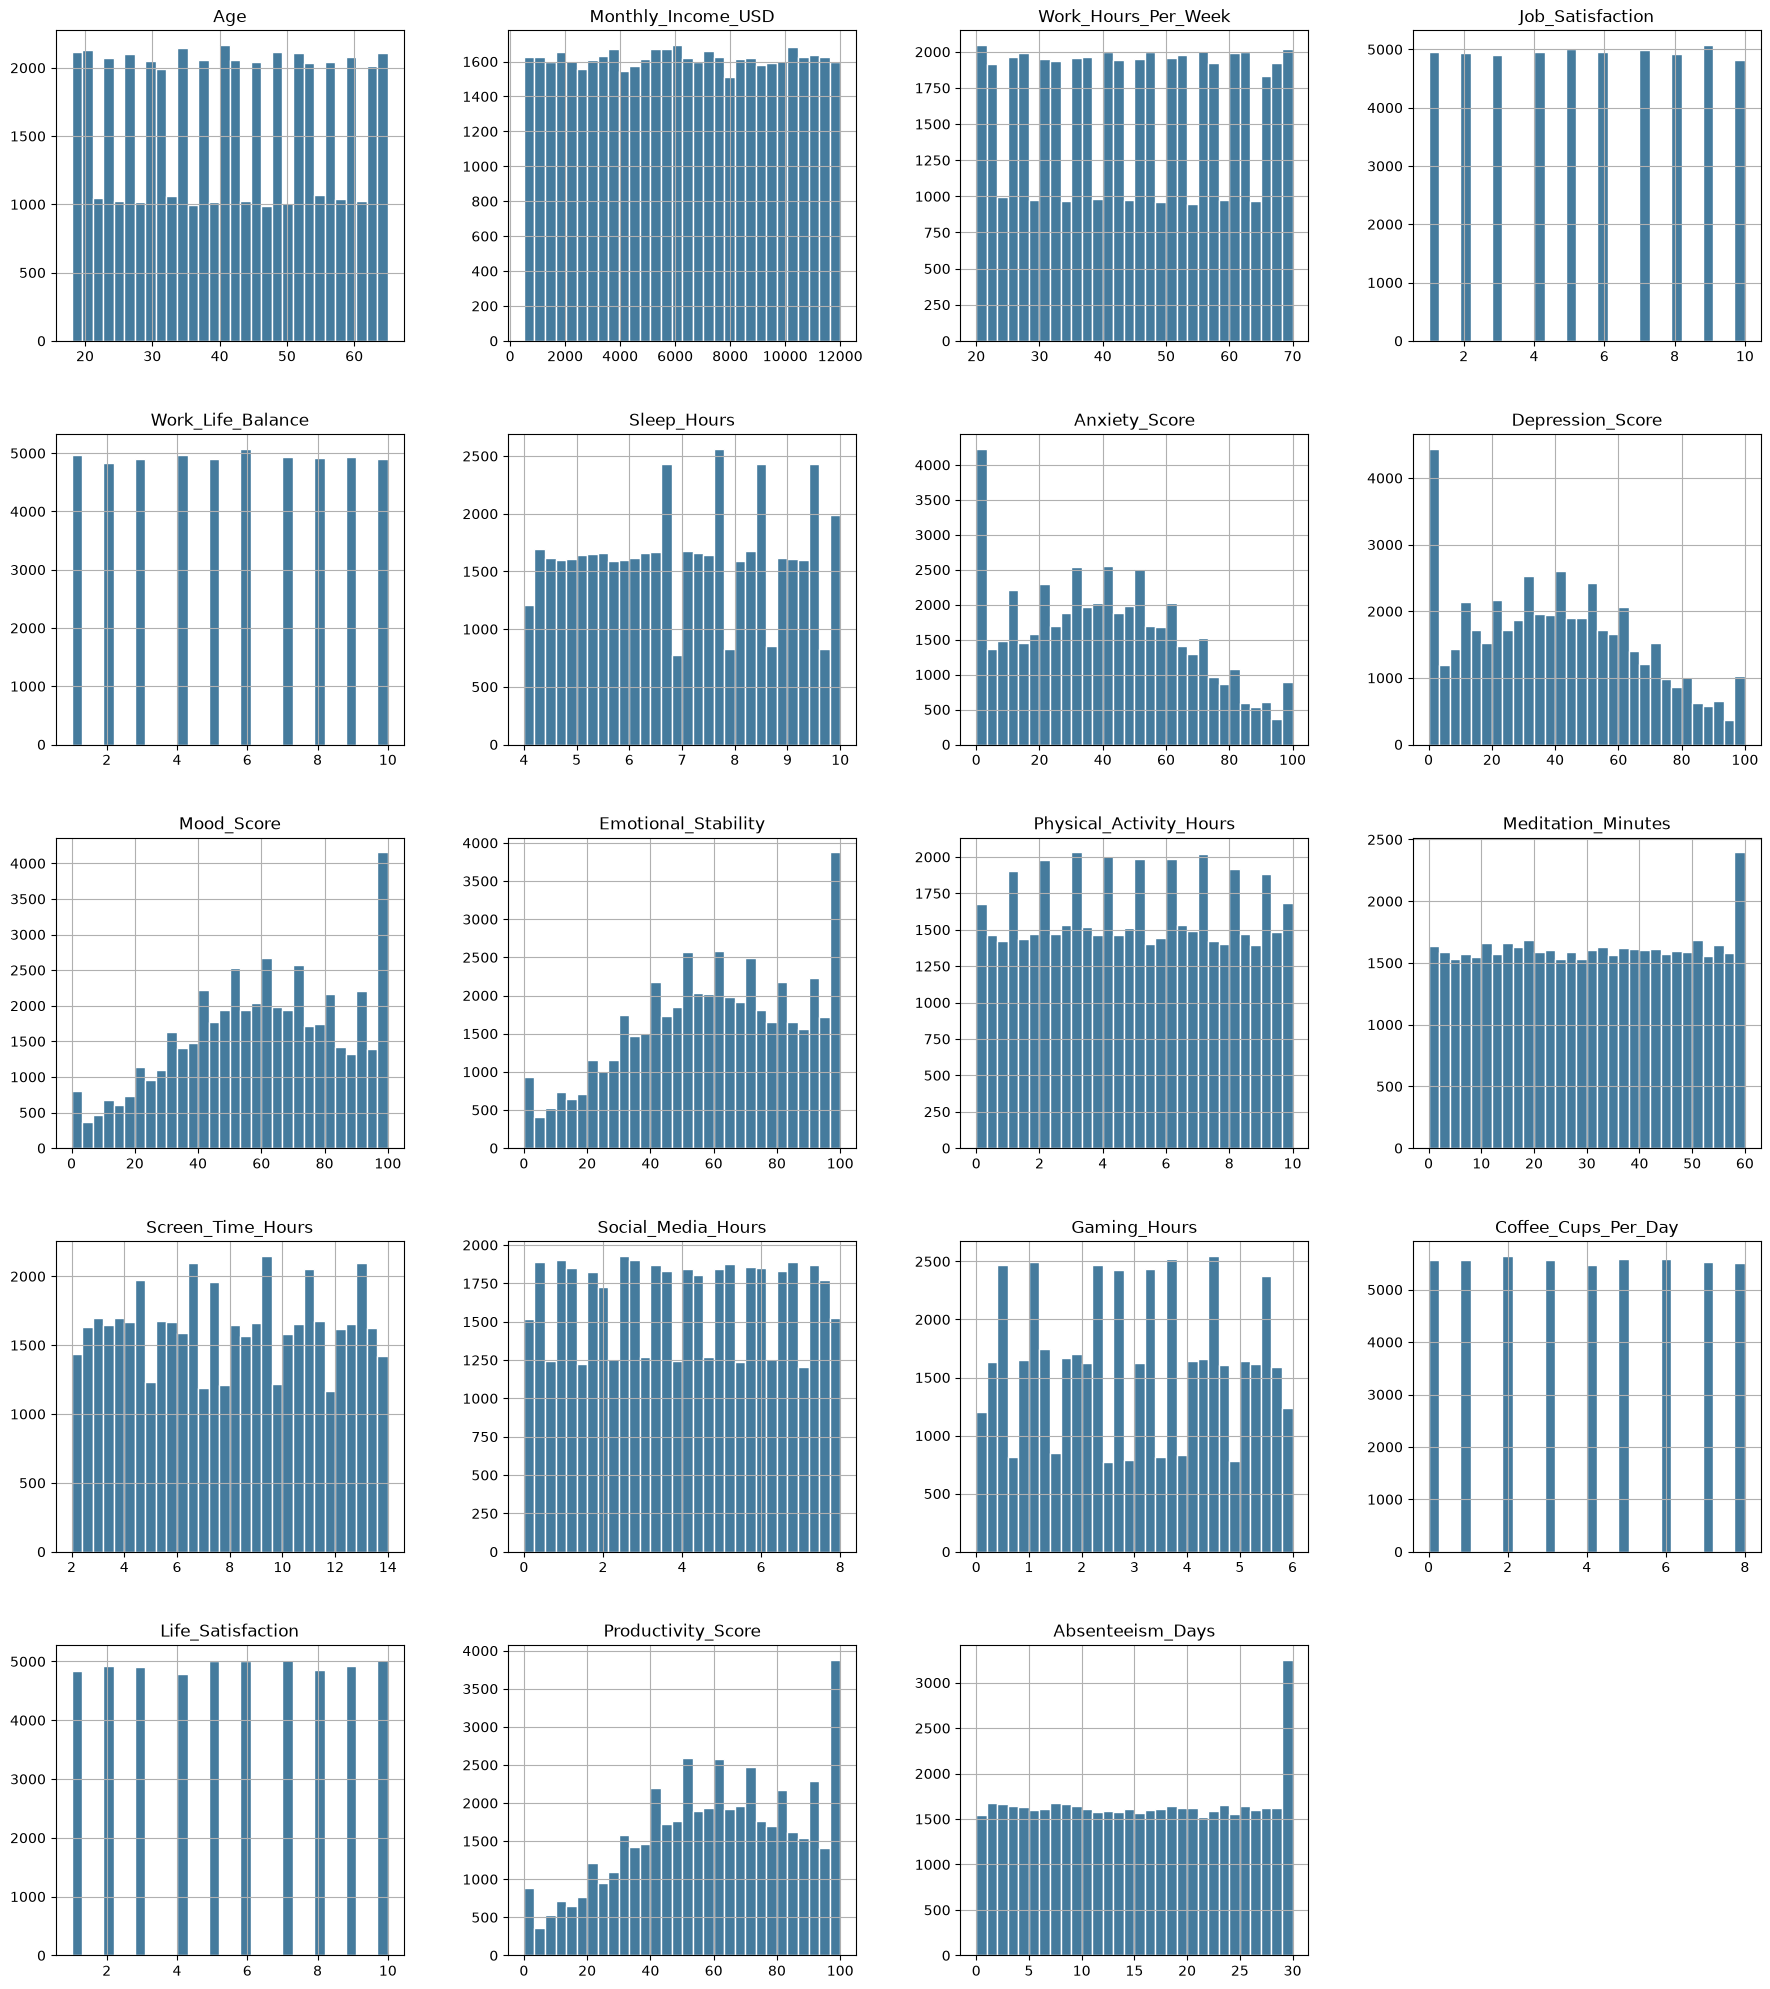

In [ ]:
df1[num_list].hist(bins=30, figsize=(22, 25), color='#457b9d', edgecolor='white', layout=(5, 4))
plt.show()


#### Fig 1.2: Most features are spread fairly evenly (flat shapes). Nothing is heavily skewed and there are no extreme outliers.

### CHART 3

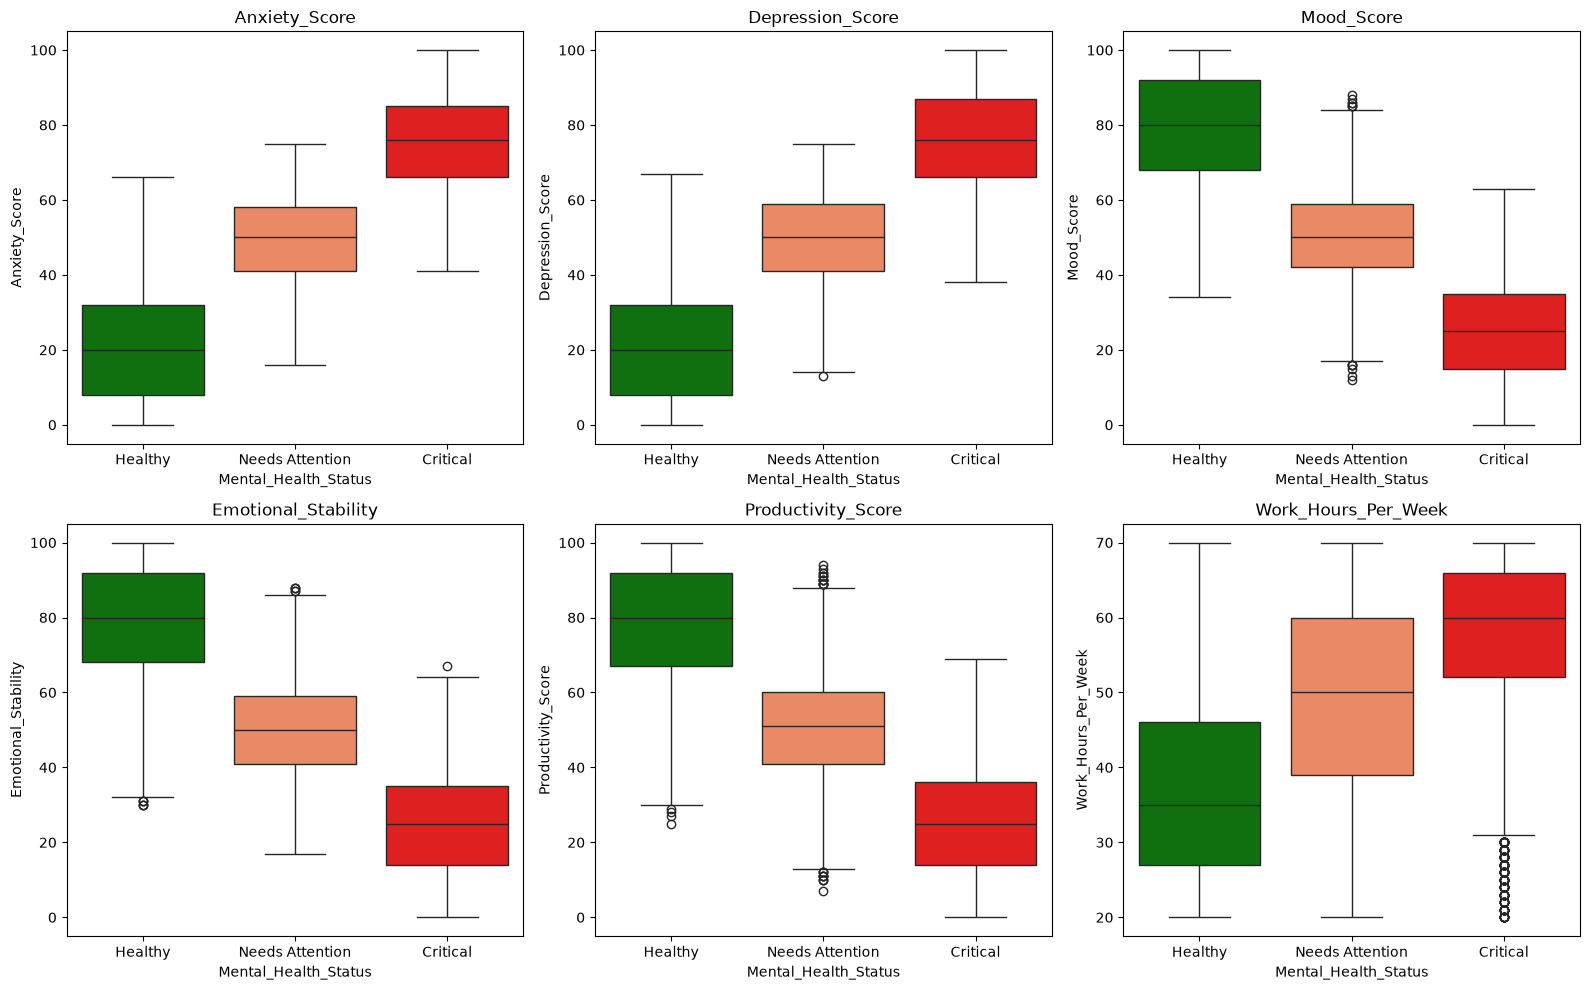

In [60]:
key = ['Anxiety_Score', 'Depression_Score', 'Mood_Score',
       'Emotional_Stability', 'Productivity_Score', 'Work_Hours_Per_Week']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for axis, col in zip(axes.ravel(), key):
    sns.boxplot(data=df1, x=TARGET, y=col, order=order, hue=TARGET,
                palette=colors, legend=False, ax=axis)
    axis.set_title(col)
plt.tight_layout()
plt.show()

#### Fig 1.3: From this box plots, there are no major overlap from the three mental health status(Healthy, Needs Attention and Critical). Critical people seem to have much anxiety and depression, much lower mood, emotional stability and productivity (about 25 vs 79 in Healthy), and work far longer hours(about 58 vs 37 per week). Needs Attention sits in between the groups on every chart. 

#### The Impact: psychological scores are the strongets predictors, and work hours is the strongest modifiable workplace factor.

### Grouped Table: Average lifestyle factors by groups/mental health status.

### TABLE 1

In [33]:
lifestyle = ['Sleep_Hours', 'Screen_Time_Hours', 'Physical_Activity_Hours', 'Meditation_Minutes',
             'Coffee_Cups_Per_Day', 'Job_Satisfaction', 'Work_Life_Balance', 'Life_Satisfaction',
             'Monthly_Income_USD', 'Age', 'Absenteeism_Days']
df.groupby(TARGET)[lifestyle].mean().loc[order].T.round(2).style.highlight_max(axis=1, color='red').highlight_min(axis=1, color='blue')

Mental_Health_Status,Healthy,Needs Attention,Critical
Sleep_Hours,7.300000,6.860000,6.450000
Screen_Time_Hours,7.040000,8.400000,9.730000
Physical_Activity_Hours,5.420000,4.790000,4.220000
Meditation_Minutes,33.340000,28.410000,24.220000
Coffee_Cups_Per_Day,3.450000,4.250000,4.970000
Job_Satisfaction,5.510000,5.490000,5.500000
Work_Life_Balance,5.510000,5.490000,5.530000
Life_Satisfaction,5.510000,5.560000,5.500000
Monthly_Income_USD,6260.920000,6225.180000,6262.950000
Age,41.420000,41.490000,41.470000


#### Observation: Critical people sleep less (6.5 vs 7.3 hours in Healthy people), use screens more (9.7 vs 7.0 hours), drink more coffee (5.0 vs 3.4 cups), exercise less (4.2 vs 5.4 hours) and meditate less (24 vs 33 minutes). The gaps are there but smaller than for those seen in the psychological scores. 

#### Job satisfaction, work-life balance, life satisfaction, income, age and absenteeism are about the same in all three groups, so alone they tell us little.

### CHART 4: Correlation heatmap

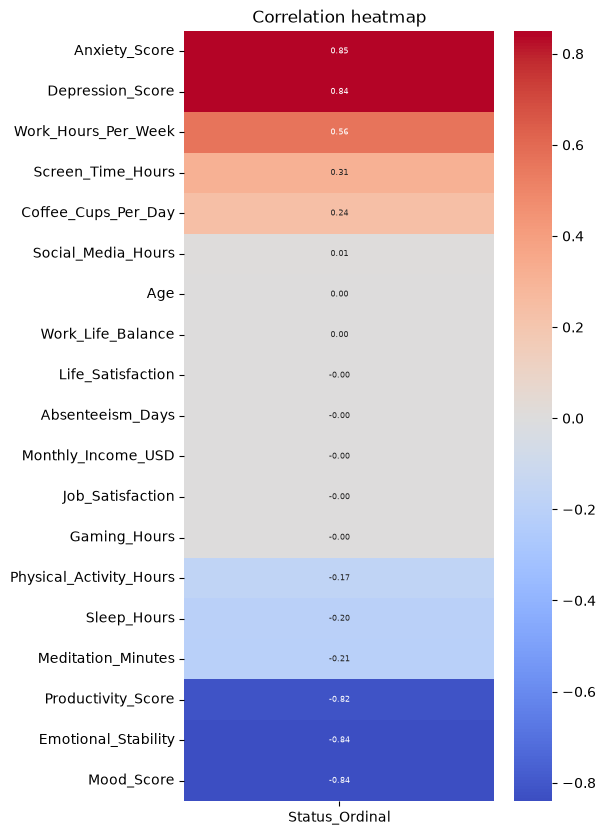

In [34]:
corr_df = df1[num_list].copy()
corr_df['Status_Ordinal'] = df1[TARGET].map({'Healthy': 0, 'Needs Attention': 1, 'Critical': 2})

target_corr = corr_df.corr()[['Status_Ordinal']].drop('Status_Ordinal').sort_values(by= 'Status_Ordinal',ascending=False).round(2)

plt.figure(figsize=(5, 10))
sns.heatmap(target_corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 6})
plt.title('Correlation heatmap')
plt.show()



#### Fig 1.4-Observation: from the chart, Anxiety, depression and work hours correlate positively with worse mental health status. Mood, emotional stability and productivity correlate strongly negatively.

#### Most other variables are near zero.

### CHART 5

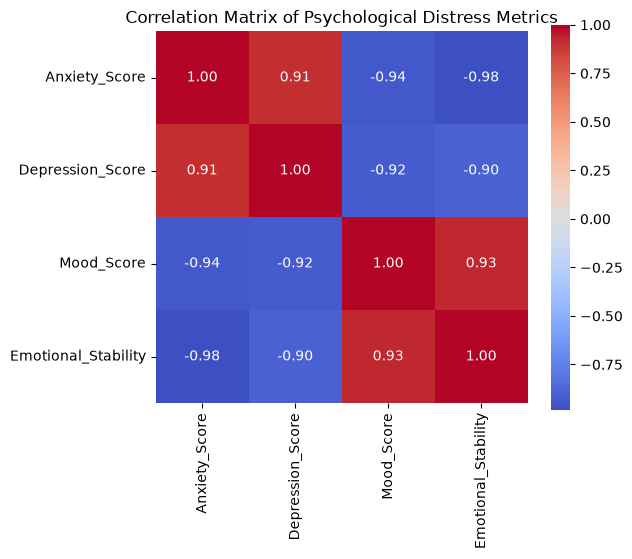

In [35]:
psych_metrics = ['Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability']

mini_corr = corr_df[psych_metrics].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(
    mini_corr, 
    annot=True, 
    cmap='coolwarm', 
    center=0, 
    fmt='.2f', 
    square=True
)

plt.title('Correlation Matrix of Psychological Distress Metrics')
plt.show()


#### Fig 1.5-Observation: The four psychological metrics as indicated above are also highly correlated with each other (about 0.9), which means they overlap(multicolinearity). To eliminate this redundancy, the features will wil be combined into one index(score) in the feature-engineering step. 

### CHART 6: CATEGORICAL FEATURES VS MENTAL HEALTH STATUS

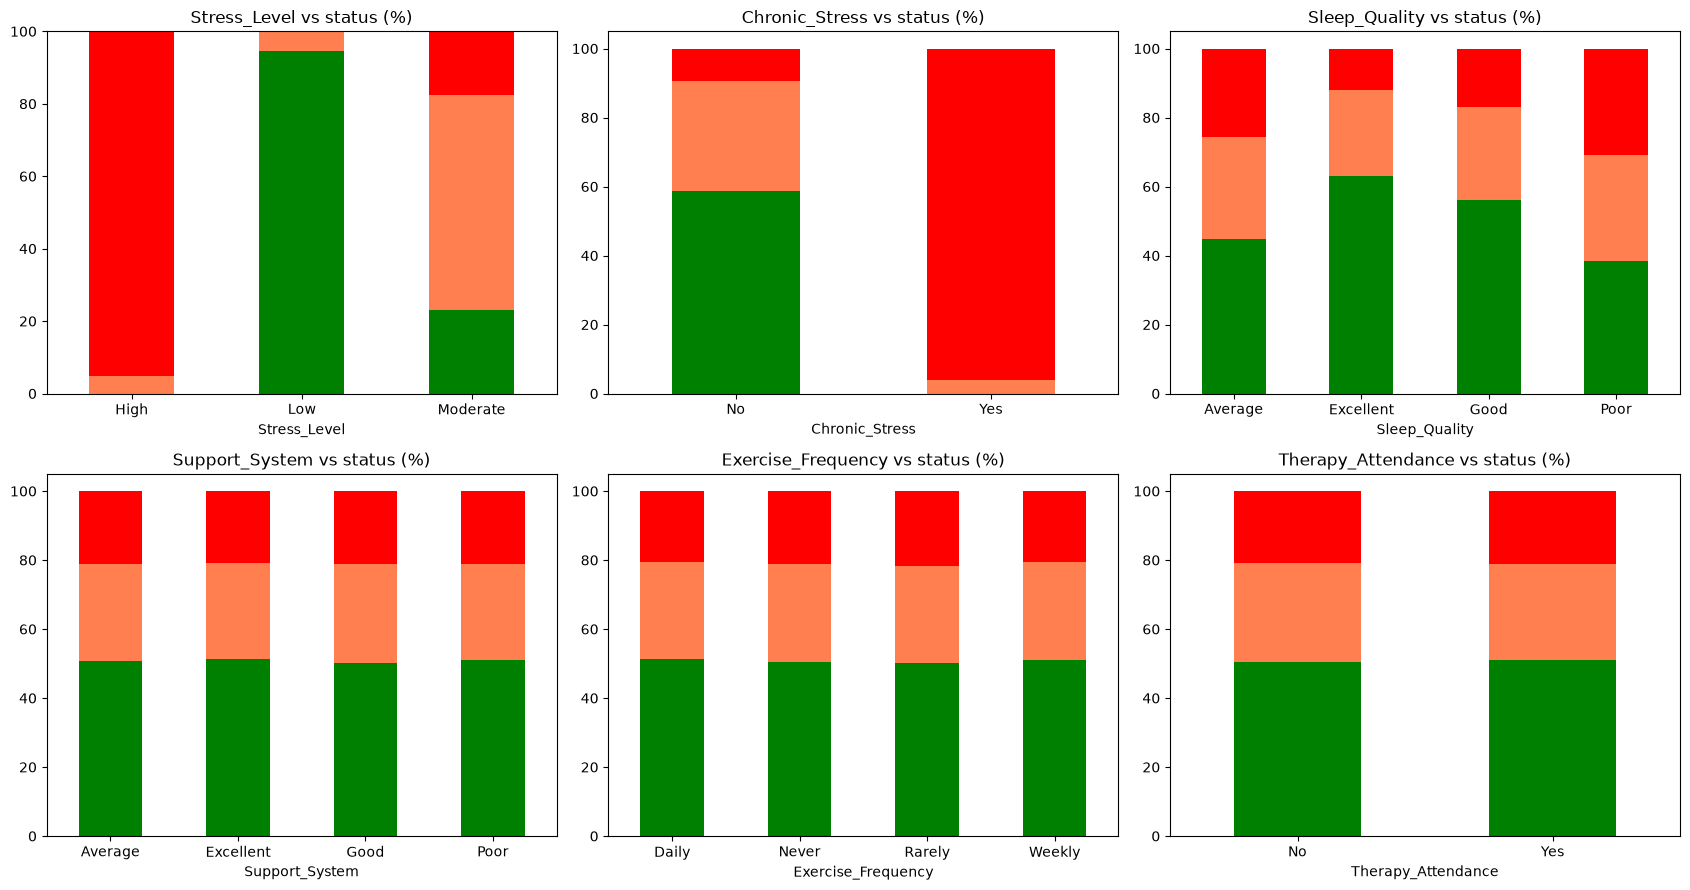

In [36]:
cat_features = ['Stress_Level', 'Chronic_Stress', 'Sleep_Quality',
        'Support_System', 'Exercise_Frequency', 'Therapy_Attendance']

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for axis, col in zip(axes.ravel(), cat_features):
    ct = pd.crosstab(df[col], df1[TARGET], normalize='index')[order] * 100
    ct.plot(kind='bar', stacked=True, color=[colors[k] for k in order],
            ax=axis, legend=False, rot=0)
    axis.set_title(col + ' vs status (%)')
plt.tight_layout()
plt.show()

#### Fig 1.6: Observations:
#### 1. Two features shows extremely important information. About 95% of individuals with High Stress are categorized as Critical, while roughly 95% with Low Stress are Healthy. Furthermore, among individuals experiencing Chronic Stress, nearly 96% are Critical and 0% are Healthy.
#### 2. Sleep quality shows a milder, yet consistent pattern where better sleeps correlates with healthier outcomes.
#### 3. Support system, exercise frequency and therapy attendance show almost no difference. 

#### Impact: stress appears to be the key lever for mental health intervention and model prediction.

### CHART 7: DOES THE LOCATION(COUNTRY) MATTER?

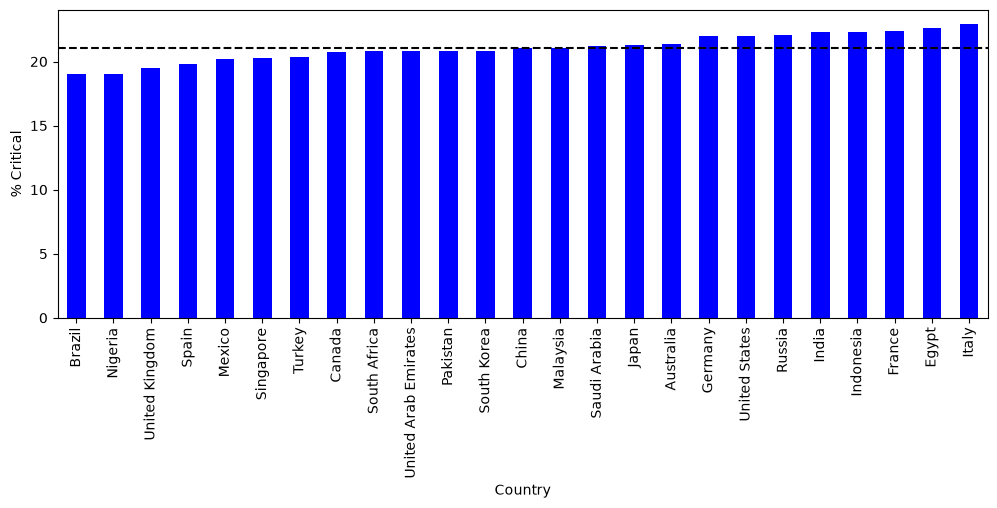

In [37]:
r = (pd.crosstab(df1['Country'], df1[TARGET], normalize='index')['Critical'] * 100).sort_values()
r.plot.bar(figsize=(12, 4), color='blue')
plt.axhline(df1[TARGET].eq('Critical').mean() * 100, color='black', linestyle='--')
plt.ylabel('% Critical')
plt.show()

#### Fig 1.7-Observation: The percentage of critical cases across the country is close to the overall 20%. This shows that, where someone lives has almost no effect.

### CHART 8: DOES OCCUPATION MATTER?

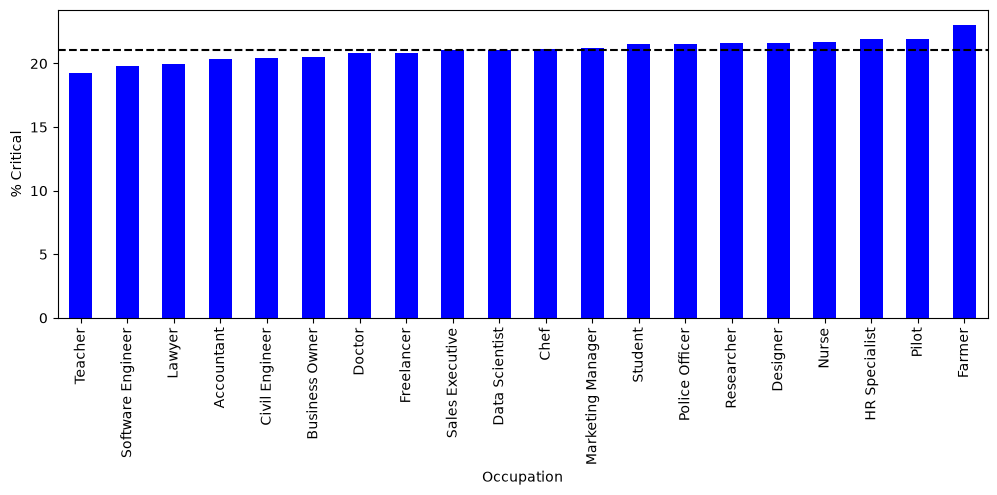

In [38]:
r = (pd.crosstab(df1['Occupation'], df1[TARGET], normalize='index')['Critical'] * 100).sort_values()
r.plot.bar(figsize=(12, 4), color='blue')
plt.axhline(df1[TARGET].eq('Critical').mean() * 100, color='black', linestyle='--')
plt.ylabel('% Critical')
plt.show()

#### Fig 1.8:The observation in country applies here as well. 

#### EDA SUMMARY:   
#### (1) psychological scores, Stress_Level and Chronic_Stress dominate;  
#### (2) work hours, sleep, screen time, coffee, exercise and meditation add moderate signal;  
#### (3) demographics, country and occupation add very little. This summary justifies the feature selection later.

## FEATURE ENGINEERING

In [61]:
def engineer(d):
    d = d.copy()
    d['Sleep_Deficit'] = (8 - d['Sleep_Hours']).clip(lower=0) 
    # Sleep deficit is calculated as the difference between 8 hours and actual sleep hours, with a lower limit of 0.
    d['Leisure_Screen_Hours'] = d['Social_Media_Hours'] + d['Gaming_Hours']
    # Leisure screen hours is calculated as the sum of social media hours and gaming hours.
    d['Psych_Distress_Index'] = (d['Anxiety_Score'] + d['Depression_Score']
                                 + (100 - d['Mood_Score']) + (100 - d['Emotional_Stability'])) / 4
    # Psychological distress index is calculated as the average of anxiety score, depression score, and the inverse of mood score and emotional stability.
    d['Work_Strain'] = d['Work_Hours_Per_Week'] * (11 - d['Work_Life_Balance'])
    # Work strain is calculated as the product of work hours per week and the difference between 11 and work-life balance.
    d['Recovery_Index'] = d['Physical_Activity_Hours'] + d['Meditation_Minutes'] / 60 + d['Sleep_Hours']
    # Recovery index is calculated as the sum of physical activity hours, meditation minutes (converted to hours), and sleep hours.
    d['Unhealthy_Habits_Count'] = d['Alcohol_Consumption'] + d['Smoking'] + (1 - d['Healthy_Diet'])
    # Unhealthy habits count is calculated as the sum of alcohol consumption, smoking, and the inverse of healthy diet.
    d['Income_Per_Work_Hour'] = d['Monthly_Income_USD'] / (d['Work_Hours_Per_Week'] * 4.33)
    # Income per work hour is calculated as the monthly income divided by the product of work hours per week and the number of weeks in a month.
    d['Satisfaction_Index'] = (d['Job_Satisfaction'] + d['Life_Satisfaction']) / 2
    # Satisfaction index is calculated as the average of job satisfaction and life satisfaction.
    d['Protective_Factors'] = (d['Support_System'] + d['Exercise_Frequency']
                               + d['Therapy_Attendance'] + d['Healthy_Diet'])
    # Protective factors is calculated as the sum of support system, exercise frequency, therapy attendance, and healthy diet.
    return d

X_train = engineer(X_train)
X_test = engineer(X_test)
print(X_train.shape)
print(X_test.shape)

(40000, 94)
(10000, 94)


In [40]:
new_features = ['Sleep_Deficit', 'Leisure_Screen_Hours', 'Psych_Distress_Index', 'Work_Strain',
             'Recovery_Index', 'Unhealthy_Habits_Count', 'Income_Per_Work_Hour',
             'Satisfaction_Index', 'Protective_Factors']
X_train[new_features].corrwith(Y_train).sort_values(key=abs, ascending=False).round(3)

Psych_Distress_Index      0.864
Income_Per_Work_Hour     -0.286
Work_Strain               0.284
Recovery_Index           -0.255
Sleep_Deficit             0.186
Unhealthy_Habits_Count    0.014
Protective_Factors       -0.012
Leisure_Screen_Hours      0.008
Satisfaction_Index       -0.005
dtype: float64

Engineered features:
This explains each of the new feature created, how it was built and why.

1. Psych_Distress_Index is the Average of anxiety, depression, reversed mood and reversed emotional stability. It combines four overlapping psychological scores into one measure of distress.
2. Work_Strain = Weekly work hours x poor work-life balance, Long hours are more harmful when work-life balance is poor.
3. Sleep_Deficit is the Hours of sleep below 8 and it measures how short of the recommended sleep a person is.
4. Recovery_Index = Physical activity + meditation (in hours) + sleep. It is total time spent recovering from stress 
5. Leisure_Screen_Hours =  Social media + gaming hours. It captures recreational screen use.
6. Unhealthy_Habits_Count = Alcohol + smoking + poor diet. It counts the risky lifestyle habits.
7. Protective_Factors = Support system + exercise frequency + therapy + healthy diet. It counts factors that protect against distress.
8. Satisfaction_Index = Average of job and life satisfaction. The overall contentment 
9. Income_Per_Work_Hour = Monthly income / monthly working hours. It is the reward received for time worked.

Interpretation: 

• From checking the correlation betwween our newly engineered features and the target, Psych_Distress_Index has an exceptional strong output(r= 0.864) and stronger than any single psychological score on its own, proving it is still the most powerful predictor. 

• Income_Per_Work_Hour, Work_Strain, Recovery_Index, and Sleep_Deficit show moderate, logical correlations (around 0.20 to 0.28).
 
• Non-Predictive Features: Unhealthy_Habits_Count, Protective_Factors, Leisure_Screen_Hours, and Satisfaction_Index have scores near 0.00, meaning they hold no linear relationship with the target.


## DATA SCALLING

In [41]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print(X_train_sc.mean().abs().max())

3.396394276933279e-16


#### Findings: After scaling, the largest absolute column mean in the training set is about 3.4e-16 (effectively zero), confirming that the features are centred. The scaler was fitted on the training data only and applied unchanged to the test data.”

## SMOTE CHECK:

#### This is needed to fix the imbalance in the data by creatimg a new, realistic Critical (and Needs Arrrention) rows. This is so because looking at the Critcal class, it is only about 21% of the data, so a model could ignore it and still look okay.

In [64]:
from imblearn.over_sampling import SMOTE

print('Before SMOTE:')
display(Y_train.value_counts().sort_index().to_frame())

smote = SMOTE(random_state=42)
X_train_bal, Y_train_bal = smote.fit_resample(X_train_sc, Y_train)

print('\nAfter SMOTE:')
display(pd.Series(Y_train_bal).value_counts().sort_index().to_frame())

print('\nTest set (should be unchanged):')
display(Y_test.value_counts().sort_index().to_frame())

Before SMOTE:


,count
Mental_Health_Status,
0,20295
1,11277
2,8428



After SMOTE:


,count
Mental_Health_Status,
0,20295
1,20295
2,20295



Test set (should be unchanged):


,count
Mental_Health_Status,
0,5074
1,2819
2,2107


### CHART 9: Distribution of Classes After SMOTE

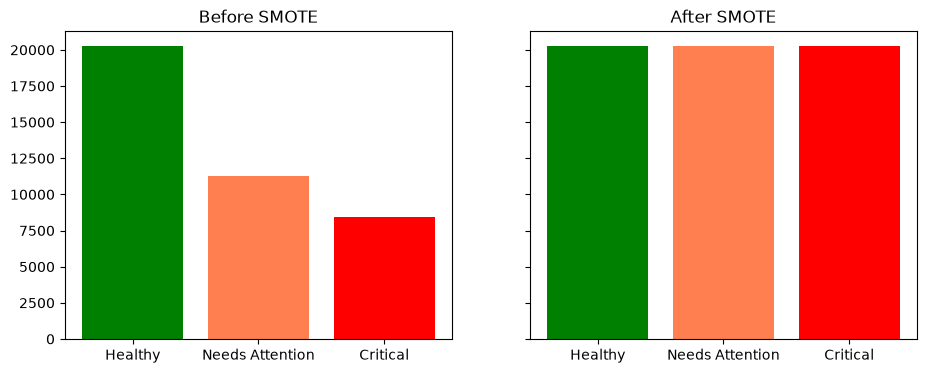

In [43]:
before = Y_train.value_counts().sort_index()
after = pd.Series(Y_train_bal).value_counts().sort_index()

fig, axis = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, s, t in zip(axis, [before, after], ['Before SMOTE', 'After SMOTE']):
    a.bar(order, s.values, color=[colors[c] for c in order])
    a.set_title(t)
plt.show()

#### Observation: Before SMOTE the classes were unequal (about 51% / 28% / 21%). After SMOTE each class has the same number of training rows, so the model can’t win by favouring Healthy. 
#### The test set was left alone so the evaluation reflects real life. From here on, i trained with X_train_bal and Y_train_bal.

## FEATURE SELECTION

94 -> 42


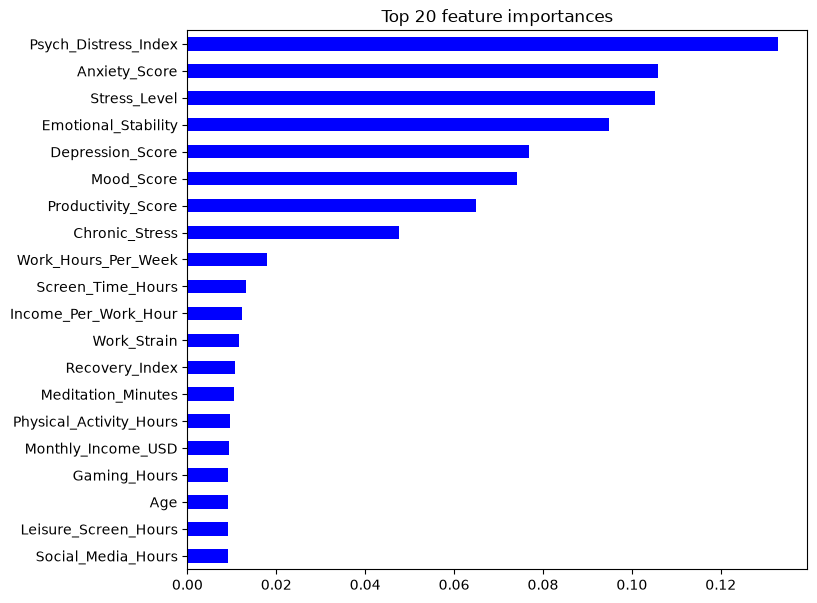

In [65]:
from sklearn.ensemble import RandomForestClassifier

rf_sel = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42)
rf_sel.fit(X_train_bal, Y_train_bal)

imp = pd.Series(rf_sel.feature_importances_, index=X_train_bal.columns).sort_values(ascending=False)
cum = imp.cumsum()
selected = list(imp.index[:int((cum < 0.95).sum()) + 1])
print(len(imp), '->', len(selected))

imp.head(20)[::-1].plot.barh(figsize=(8, 7), color='blue')
plt.title('Top 20 feature importances')
plt.show()

In [68]:
X_train_final = X_train_bal[selected]   
X_train_sc_final = X_train_sc[selected]    
X_test_sc_final = X_test_sc[selected]  

print("Old features count:", X_train_bal.shape[1])
print("New optimized features count:", X_train_final.shape[1])

Old features count: 94
New optimized features count: 42


#### Interpretation:  

Importance is concentrated in a small group of features; the engineered Psych_Distress_Index (ranked first), the raw psychological scores, Stress_Level, Chronic_Stress and Work_Hours_Per_Week / Work_Strain. 42 of 94 features were kept (95% cumulative importance). 

All 52 dropped features were country, occupation, gender and employment-status dummy columns, which have almost no importance. 
This agrees with the EDA, where geography and job title did not matter. Psych_Distress_Index ranking first shows that the feature engineering was useful.

## BUILDING THE MODEL

In [69]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(objective='multi:softprob', n_estimators=200, max_depth=5,
                             learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                             eval_metric='mlogloss', n_jobs=-1, random_state=42),
}

trained = {}
for name, model in models.items():
    trained[name] = model.fit(X_train_final, Y_train_bal)
    print(name, 'trained')

Logistic Regression trained
Random Forest trained
XGBoost trained


In [70]:
preds, probas = {}, {}
for name in models:
    preds[name] = trained[name].predict(X_test_sc_final)          # the predicted class
    probas[name] = trained[name].predict_proba(X_test_sc_final)   # the probability of each class

## CROSS-VALIDATION

In [71]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
from imblearn.pipeline import Pipeline as ImbPipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, m in models.items():
    pipe = ImbPipeline([('smote', SMOTE(random_state=42)), ('model', clone(m))])
    s = cross_validate(pipe, X_train_sc_final, Y_train, cv=cv, scoring=['accuracy', 'f1_macro', 'roc_auc_ovr'])
    cv_rows.append({'Model': name,
                    'CV Accuracy': round(s['test_accuracy'].mean(), 4),
                    'CV Macro F1': round(s['test_f1_macro'].mean(), 4),
                    'CV ROC-AUC': round(s['test_roc_auc_ovr'].mean(), 4)})
pd.DataFrame(cv_rows).set_index('Model')

,CV Accuracy,CV Macro F1,CV ROC-AUC
Model,,,
Logistic Regression,0.8222,0.8108,0.9492
Random Forest,0.8234,0.8127,0.9497
XGBoost,0.8234,0.8112,0.9506


#### Cross-validation Findings: 
Three models were tested (Logistic Regression, Random Forest, and XGBoost) using a 5-step test.

 Accuracy and confidence for all three models were about 0.82 and 0.95 ROC-AUC score respectively. This confirmsn that the models are stable and not over-fitted to one particular split of the data.

 The winner is Random Forest: It got the highest balance score (0.8127 Macro F1) and tied for the best overall accuracy (0.8234).



## EVALUATION ON THE TEST SET

In [49]:
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, classification_report)
from sklearn.preprocessing import label_binarize

rows = []
for name in models:
    rec = recall_score(Y_test, preds[name], average=None)
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(Y_test, preds[name]),
                 'Macro Precision': precision_score(Y_test, preds[name], average='macro'),
                 'Macro F1': f1_score(Y_test, preds[name], average='macro'),
                 'Recall Healthy': rec[0], 'Recall Needs Attention': rec[1], 'Recall Critical': rec[2],
                 'ROC-AUC': roc_auc_score(Y_test, probas[name], multi_class='ovr', average='macro')})
results = pd.DataFrame(rows).set_index('Model').round(4)
results

,Accuracy,Macro Precision,Macro F1,Recall Healthy,Recall Needs Attention,Recall Critical,ROC-AUC
Model,,,,,,,
Logistic Regression,0.8222,0.8090,0.8122,0.8431,0.7606,0.8543,0.9499
Random Forest,0.8263,0.8181,0.8165,0.8547,0.7744,0.8272,0.9497
XGBoost,0.8281,0.8214,0.8162,0.8725,0.7641,0.8068,0.9509


#### Final Test Evaluation:

• All three models performed consistently well on the final test exam, maintaining an overall accuracy of about 0.82-0.83 and high confidence (0.95 ROC-AUC).

• Random Forest achieved the highest overall balance score (0.82 Macro F1).

• However, Logistic Regression seem to be the best at catching dangerous cases, achieving the highest recall for the Critical class (0.85). 

In [50]:
for name in models:
    print('=====', name, '=====')
    print(classification_report(Y_test, preds[name], target_names=order, digits=3))

===== Logistic Regression =====
                 precision    recall  f1-score   support

        Healthy      0.929     0.843     0.884      5074
Needs Attention      0.660     0.761     0.707      2819
       Critical      0.837     0.854     0.846      2107

       accuracy                          0.822     10000
      macro avg      0.809     0.819     0.812     10000
   weighted avg      0.834     0.822     0.826     10000

===== Random Forest =====
                 precision    recall  f1-score   support

        Healthy      0.921     0.855     0.887      5074
Needs Attention      0.665     0.774     0.715      2819
       Critical      0.869     0.827     0.848      2107

       accuracy                          0.826     10000
      macro avg      0.818     0.819     0.816     10000
   weighted avg      0.838     0.826     0.830     10000

===== XGBoost =====
                 precision    recall  f1-score   support

        Healthy      0.910     0.872     0.891      5074
Nee

#### Interpretation of results: 

All three models perform almost the same. Test accuracy is 82.2% (Logistic Regression), 82.6% (Random Forest) and 82.8% (XGBoost), and macro F1 is 0.812, 0.816 and 0.816. This agree with the cross-validation scores, so the models are stable and not over-fitted. The gaps between models are under 1 percentage point.

The weakest class is Needs Attention (precision about 0.66, F1 about 0.71 to 0.72). It is the middle group, so its boundaries touch both Healthy and Critical, which makes it harder to separate. Healthy (F1 about 0.88 to 0.89) and Critical (F1 about 0.85) are identified much better.

For Critical, Logistic Regression catches the most real cases (recall 0.854), while Random Forest is more precise (0.869 vs 0.837) but catches fewer (0.827). Since missing a Critical person is the costliest error in screening, recall for Critical is an important point when choosing a model.

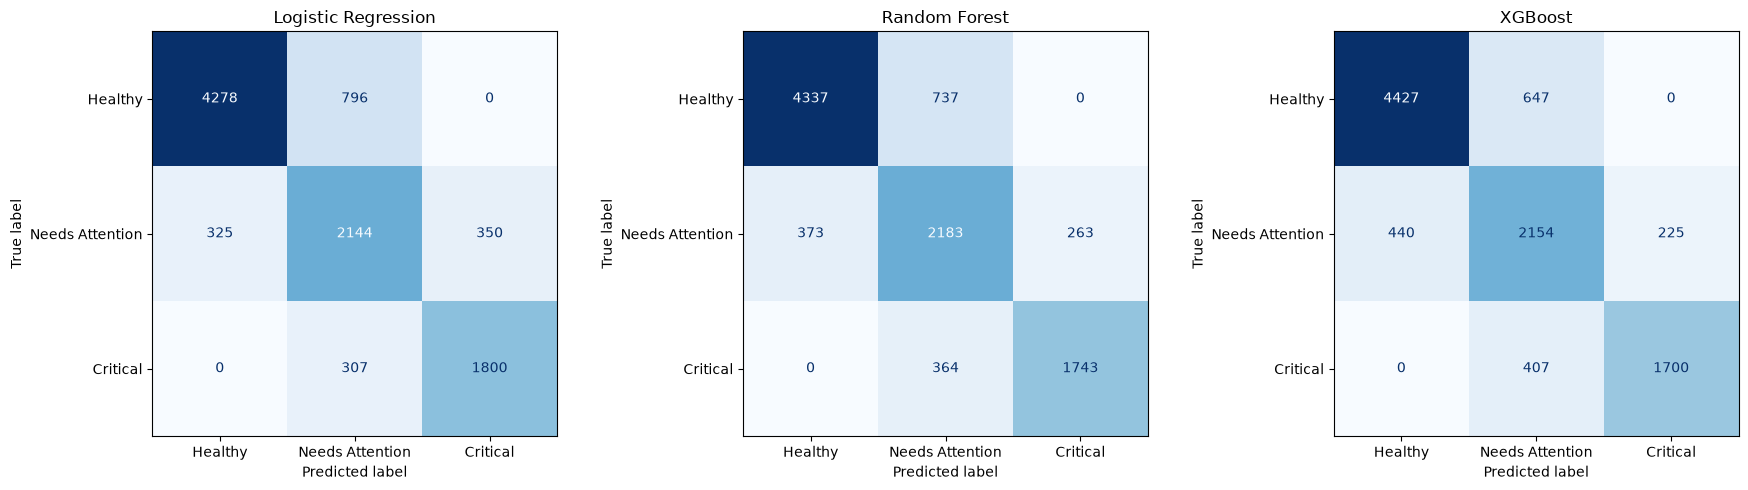

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay(confusion_matrix(Y_test, preds[name]),
                           display_labels=order).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout()
plt.show()

#### Interpretation of the confusion matrices: 
Rows are the true class and columns are the predicted class. The diagonal shows correct predictions.

1. Across all three models, no Healthy person was predicted Critical and no Critical person was predicted Healthy (both corners are 0). Every error is between neighbouring classes, so no model ever labels a Critical person as Healthy.

2. The most important error is Critical predicted as Needs Attention: 307 people for Logistic Regression (14.6% of the 2,107 Critical cases), 364 for Random Forest (17.3%) and 407 for XGBoost (19.3%). These people are still flagged, but they would be under-prioritised.

3. The most common error overall is Healthy predicted as Needs Attention (796, 737 and 647 people). These are false alarms, which are less costly than missing a Critical case.

4. Trade-off between models: Logistic Regression catches the most Critical cases (1,800 correct, recall 85.4%) but raises the most false alarms. XGBoost raises the fewest false alarms but misses the most Critical cases. Random Forest sits in between.

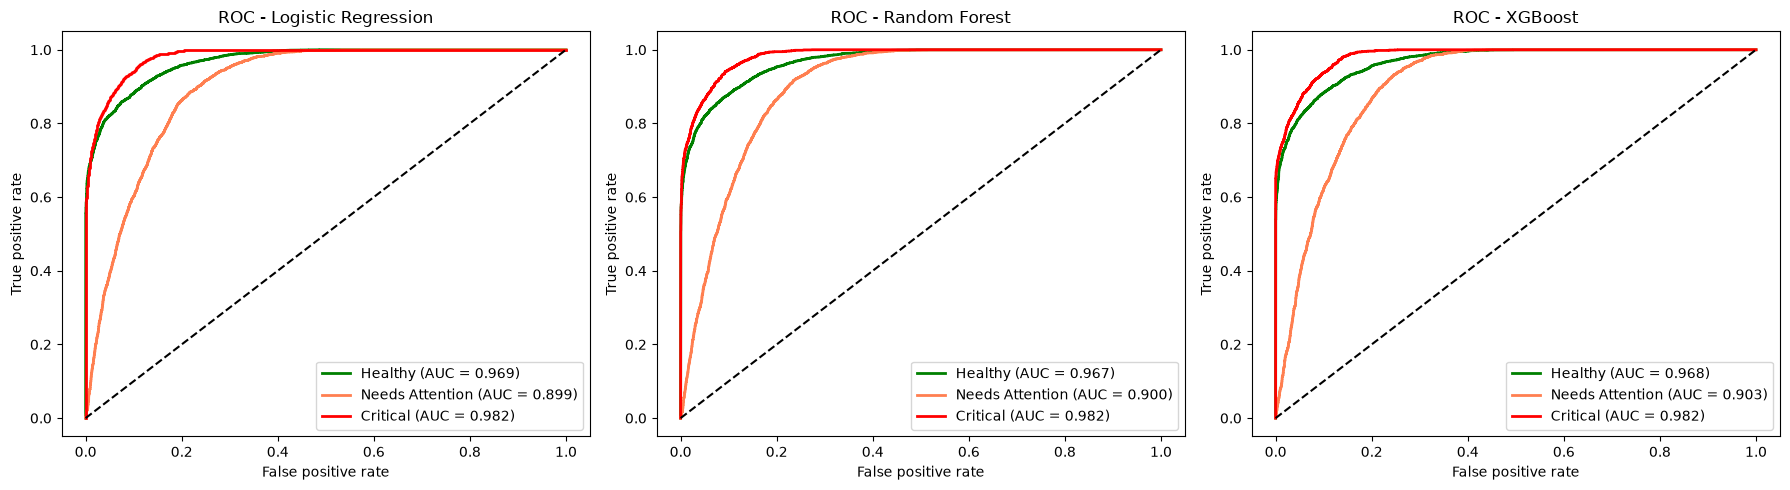

In [52]:
from sklearn.preprocessing import label_binarize

y_bin = label_binarize(Y_test, classes=[0, 1, 2])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, name in zip(axes, models):
    for i, cls in enumerate(order):
        fpr, tpr, _ = roc_curve(y_bin[:, i], probas[name][:, i])
        axis.plot(fpr, tpr, color=colors[cls], lw=2, label=f'{cls} (AUC = {auc(fpr, tpr):.3f})')
    axis.plot([0, 1], [0, 1], 'k--')
    axis.set_title('ROC - ' + name)
    axis.set_xlabel('False positive rate')
    axis.set_ylabel('True positive rate')
    axis.legend(loc='lower right')
plt.tight_layout()
plt.show()

#### Interpretation of the ROC curves: 
An AUC of 0.5 (the dashed diagonal) is random guessing and 1.0 is perfect. The one-vs-rest AUC for Critical is 0.982 for all three models and for Healthy it is 0.967 to 0.969, so every model separates these two classes very well. Needs Attention has a lower AUC (0.899 for Logistic Regression, 0.900 for Random Forest and 0.903 for XGBoost) because it is the middle group and overlaps with both neighbours, which matches the confusion matrices. The curves of the three models almost overlap, so they rank people equally well, with macro AUC of about 0.95 for each.

In [53]:
results

,Accuracy,Macro Precision,Macro F1,Recall Healthy,Recall Needs Attention,Recall Critical,ROC-AUC
Model,,,,,,,
Logistic Regression,0.8222,0.8090,0.8122,0.8431,0.7606,0.8543,0.9499
Random Forest,0.8263,0.8181,0.8165,0.8547,0.7744,0.8272,0.9497
XGBoost,0.8281,0.8214,0.8162,0.8725,0.7641,0.8068,0.9509


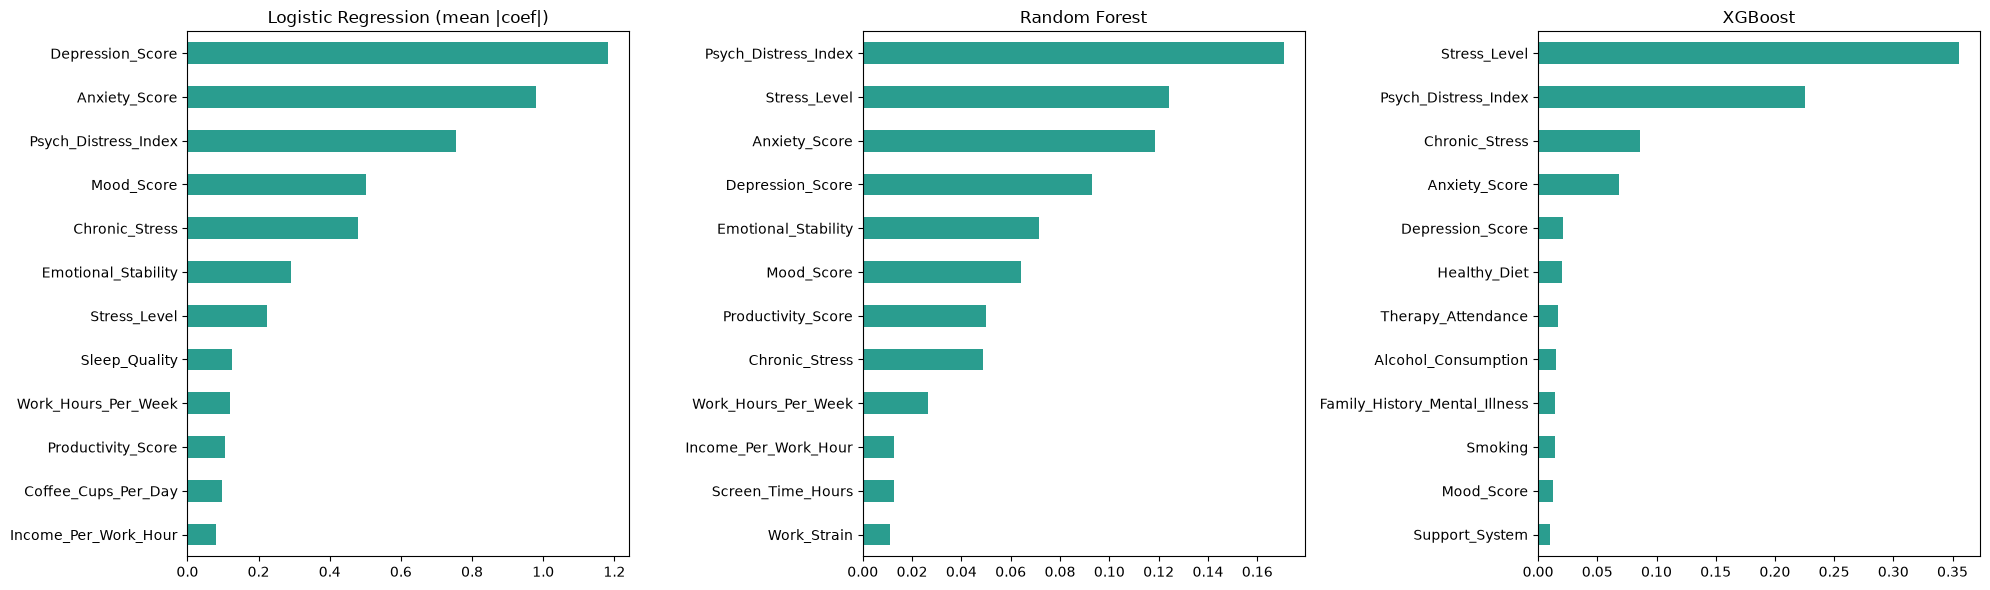

In [73]:
selected_names = list(X_train_final.columns)
lr_imp = pd.Series(np.abs(trained['Logistic Regression'].coef_).mean(axis=0), index=selected_names)
rf_imp = pd.Series(trained['Random Forest'].feature_importances_, index=selected_names)
xg_imp = pd.Series(trained['XGBoost'].feature_importances_, index=selected_names)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, s, t in zip(axes, [lr_imp, rf_imp, xg_imp], ['Logistic Regression (mean |coef|)', 'Random Forest', 'XGBoost']):
    s.sort_values().tail(12).plot.barh(ax=ax, color='#2a9d8f')
    ax.set_title(t)
plt.tight_layout()
plt.show()

#### Interpretation of variable importance:
All three models agree on the main drivers: the psychological scores (depression, anxiety, mood, emotional stability), the engineered Psych_Distress_Index, Stress_Level and Chronic_Stress. XGBoost relies most on Stress_Level (about 34% of importance) and Psych_Distress_Index (about 24%). 

- Logistic Regression gives its largest weights to Depression_Score, Anxiety_Score and Psych_Distress_Index.
- Random Forest ranks Psych_Distress_Index first, followed by Stress_Level, Anxiety_Score and Depression_Score.
- XGBoost relies most heavily on Stress_Level (about 36% of its importance) and Psych_Distress_Index (about 22%). Beyond Chronic_Stress and Anxiety_Score, every other feature contributes very little to it.

The engineered Psych_Distress_Index is in the top three for all three models, which shows the feature engineering was useful. Work hours, productivity and sleep quality add a smaller contribution. The scales differ between models (coefficients vs importance shares), so the bars should be compared within each chart, not across charts.

In [74]:
best_name = results.sort_values(['Macro F1', 'Recall Critical'], ascending=False).index[0]
print('Best model:', best_name)
results.loc[[best_name]]

Best model: Random Forest


,Accuracy,Macro Precision,Macro F1,Recall Healthy,Recall Needs Attention,Recall Critical,ROC-AUC
Model,,,,,,,
Random Forest,0.8263,0.8181,0.8165,0.8547,0.7744,0.8272,0.9497


#### Model selection: 

Random Forest has the highest macro F1 (0.8165), which is the main selection metric because it treats all three classes equally. 
XGBoost is practically tied (0.8162) and has the highest accuracy (0.8281) and ROC-AUC (0.9509). 
Logistic Regression catches the most Critical cases (recall 0.8543). 
The differences between the models are very small (under half a percentage point), so any of them would be acceptable. Random Forest is selected because it ranks first on macro F1.

In [75]:
import joblib, os

artifacts = {
    'model': trained[best_name],
    'model_name': best_name,
    'scaler': scaler,
    'fill_values': fill_values,
    'all_columns': list(X_train.columns),
    'selected_features': selected,
    'class_order': order,
}
joblib.dump(artifacts, 'mental_health_artifacts.joblib', compress=3)
X_train_final.sample(500, random_state=42).to_csv('shap_background.csv', index=False)

print(os.path.getsize('mental_health_artifacts.joblib') / 1e6, 'MB')

23.323948 MB


## Conclusion and Recommendations

#### Result: 
Random Forest was selected as the best model because it has the highest macro F1 (0.8165). On the untouched test set it reaches 82.6% accuracy, a macro ROC-AUC of 0.950 and a recall of 82.7% for the Critical class. Logistic Regression and XGBoost perform almost identically (accuracy 82.2% and 82.8%), and cross-validation confirms the results are stable. No model ever confused a Healthy person with a Critical person, so all errors are between neighbouring classes.

What drives mental health status: psychological distress scores (anxiety, depression, mood, emotional stability), stress level and chronic stress dominate. Longer working hours, shorter sleep, more screen time and caffeine, and less physical activity and meditation add a smaller signal. Country, occupation, gender and employment status add almost nothing.

#### Recommendations
1. Use the model as a screening tool, not a diagnosis. Refer Critical predictions for professional assessment and offer Needs Attention predictions a supportive check-in.
2. Prioritise stress management. Stress_Level and Chronic_Stress are among the strongest indicators, so reducing sustained stress offers the biggest potential benefit.
3. Address long working hours, the strongest modifiable workplace factor (about 58 hours per week for Critical vs 37 for Healthy).
4. Support recovery habits: sleep, physical activity, meditation, and lower screen time and caffeine.
5. If missing a Critical case is costlier than a false alarm, flag people at a lower Critical probability. About 17% of true Critical cases were labelled Needs Attention by the Random Forest.
6. Screen on psychological and stress indicators, not on demographics. Location and job title do not help prediction.

#### Limitations: 
the data is synthetic, so results may not carry over to real populations; about 83% accuracy looks like the limit for this set of features; the Needs Attention group is the hardest to separate; and Burnout_Score, Burnout_Risk and AI_Wellness_Recommendation were deliberately excluded to avoid target leakage. 

#### Next steps: 
validate on real data, calibrate the predicted probabilities and check fairness across groups.